# EXP03 · Thêm Batch Normalization

Đánh giá tác động của **Batch Normalization** (`BatchNorm2d` sau mỗi lớp `Conv2d` và `BatchNorm1d` sau lớp `Linear` ẩn) lên các kiến trúc CNN trên tập FER2013:
- **Baseline + BN** (3 lớp Conv)
- **DeeperCNN + BN** (4 lớp Conv)
- **Improved V2 + BN** (6 lớp Conv)
- **Improved V3 + BN** (8 lớp Conv)


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Image, display
from torch import nn
import warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="torch.jit")

cwd = Path.cwd()
project = next(
    (path for path in (cwd, cwd.parent, cwd / "BTL02")
     if (path / "configs/exp03_baseline_bn.yaml").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Mở notebook từ thư mục repo, BTL02 hoặc BTL02/notebooks.")
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from evaluate import evaluate_checkpoint
from models import build_model
from train import run_experiment, select_device

# Các lượt đối chứng từ EXP01 và EXP02
REFERENCE_RUNS = {
    "Baseline (EXP01)": project / "results/EXP001_Baseline/20261120_122107_175923",
    "DeeperCNN (EXP02)": project / "results/EXP02/deeper_cnn/20261124_125301_044663",
    "Improved V2 (EXP02)": project / "results/EXP02/improved_cnn_v2/20261124_125450_669946",
    "Improved V3 (EXP02)": project / "results/EXP02/improved_cnn_v3/20261124_125802_658900",
}

EXP03_CONFIG_PATHS = {
    "Baseline + BN": project / "configs/exp03_baseline_bn.yaml",
    "DeeperCNN + BN": project / "configs/exp03_deeper_cnn_bn.yaml",
    "Improved V2 + BN": project / "configs/exp03_improved_v2_bn.yaml",
    "Improved V3 + BN": project / "configs/exp03_improved_v3_bn.yaml",
}
exp03_configs = {
    name: yaml.safe_load(path.read_text(encoding="utf-8"))
    for name, path in EXP03_CONFIG_PATHS.items()
}

## Kiến trúc và đối chứng

| Mô hình | Số lớp Conv | Kênh đầu ra | Batch Normalization | Tensor trước Flatten |
|---|---:|---|---|---|
| Baseline + BN | 3 | 32 → 64 → 128 | `BatchNorm2d` sau mỗi Conv + `BatchNorm1d(128)` | 128 × 6 × 6 |
| DeeperCNN + BN | 4 | 32 → 64 → 128 → 128 | `BatchNorm2d` sau mỗi Conv + `BatchNorm1d(128)` | 128 × 6 × 6 |
| Improved V2 + BN | 6 | 32 → 32 → 64 → 64 → 128 → 128 | `BatchNorm2d` sau mỗi Conv + `BatchNorm1d(128)` | 128 × 6 × 6 |
| Improved V3 + BN | 8 | 32 → 32 → 64 → 64 → 128 → 128 → 256 → 256 | `BatchNorm2d` sau mỗi Conv + `BatchNorm1d(128)` | 256 × 3 × 3 |

Các lớp `Conv2d` và `Linear` đứng trước `BatchNorm` được đặt `bias=False` để tránh tham số dư thừa vì `BatchNorm` đã có tham số dịch chuyển $\beta$. Toàn bộ siêu tham số huấn luyện (split 80/20, seed 42, batch size 64, Adam `lr=0.001`, 30 epoch) giữ nguyên để cô lập tác động của Batch Normalization.

In [2]:
baseline_config = yaml.safe_load((REFERENCE_RUNS["Baseline (EXP01)"] / "config.yaml").read_text(encoding="utf-8"))
training_keys = ("data_dir", "epochs", "batch_size", "learning_rate", "seed", "device")
for name, config in exp03_configs.items():
    for key in training_keys:
        if config[key] != baseline_config[key]:
            raise ValueError(f"{name} khác baseline ở cấu hình {key}.")

architecture = {}
for name, config in exp03_configs.items():
    model = build_model(config["model"])
    channels = [layer.out_channels for layer in model.modules() if isinstance(layer, nn.Conv2d)]
    bn_layers = sum(1 for layer in model.modules() if isinstance(layer, (nn.BatchNorm2d, nn.BatchNorm1d)))
    architecture[name] = {
        "Model key": config["model"],
        "Số lớp tích chập": len(channels),
        "Số lớp BatchNorm": bn_layers,
        "Kênh theo từng lớp": " → ".join(map(str, channels)),
        "Số tham số": sum(parameter.numel() for parameter in model.parameters()),
    }

display(pd.DataFrame.from_dict(architecture, orient="index"))

,Model key,Số lớp tích chập,Số lớp BatchNorm,Kênh theo từng lớp,Số tham số
Baseline + BN,baseline_bn,3,4,32 → 64 → 128,683879
DeeperCNN + BN,deeper_cnn_bn,4,5,32 → 64 → 128 → 128,831591
Improved V2 + BN,improved_cnn_v2_bn,6,7,32 → 32 → 64 → 64 → 128 → 128,877863
Improved V3 + BN,improved_cnn_v3_bn,8,9,32 → 32 → 64 → 64 → 128 → 128 → 256 → 256,1468711


## Huấn luyện hoặc dùng lại kết quả đã lưu

Mặc định `RUN_DIRS` đặt là `None` để tự động huấn luyện các biến thể EXP03 khi chạy notebook lần đầu. Sau khi huấn luyện xong, điền đường dẫn thư mục run (ví dụ `"results/EXP03/improved_cnn_v2_bn/20261124_..."`) vào `RUN_DIRS` để tái sử dụng checkpoint mà không cần train lại.

In [3]:
RUN_DIRS = {
    "Baseline + BN": None,
    "DeeperCNN + BN": None,
    "Improved V2 + BN": None,
    "Improved V3 + BN": None,
}

runs = dict(REFERENCE_RUNS)
for name, config_path in EXP03_CONFIG_PATHS.items():
    saved_path = RUN_DIRS[name]
    if saved_path is None:
        run = run_experiment(config_path)
    else:
        run = project / saved_path
        saved_config = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
        for key in ("experiment", "model", *training_keys):
            if saved_config[key] != exp03_configs[name][key]:
                raise ValueError(f"Lượt đã lưu của {name} khác cấu hình ở {key}.")
    runs[name] = run
    print(f"{name} · {run.relative_to(project)}")

D:\Users\Admin\source\repos\DeepLearning_Group\BTL02\results\EXP03\baseline_bn\20261125_091949_889469 cuda {'input': [64, 1, 48, 48], 'output': [64, 7], 'loss': 2.0075526237487793, 'finite_gradients': True}
01/30  train 1.4320 44.74%  val 1.3468 49.08%
02/30  train 1.1713 55.75%  val 1.2004 53.99%
03/30  train 1.0161 61.94%  val 1.1952 54.75%
04/30  train 0.8592 68.71%  val 1.1529 57.68%
05/30  train 0.6802 75.46%  val 1.2530 55.90%
06/30  train 0.5018 82.70%  val 1.3863 55.10%
07/30  train 0.3422 89.05%  val 1.4723 56.39%
08/30  train 0.2301 92.81%  val 1.5963 55.63%
09/30  train 0.1614 95.52%  val 1.6749 57.00%
10/30  train 0.1238 96.59%  val 1.8415 56.93%
11/30  train 0.0956 97.57%  val 1.9682 56.70%
12/30  train 0.0964 97.32%  val 2.2115 56.17%
13/30  train 0.0932 97.27%  val 2.0567 56.65%
14/30  train 0.0824 97.79%  val 2.0559 55.64%
15/30  train 0.0880 97.44%  val 2.1428 57.23%
16/30  train 0.0653 98.29%  val 2.1626 57.11%
17/30  train 0.0624 98.38%  val 2.3202 56.81%
18/30  trai

## Macro F1 và confusion matrix trên tập validation

Các kết quả được tính trên split validation cố định từ `train.csv`, không dùng tập test.

Validation accuracy 57.68% | Macro F1 0.5357
Validation accuracy 59.94% | Macro F1 0.5491
Validation accuracy 60.54% | Macro F1 0.5605
Validation accuracy 61.44% | Macro F1 0.5553


,Validation accuracy (%),Validation macro F1
Baseline (EXP01),55.2072,0.4861
DeeperCNN (EXP02),54.4584,0.4874
Improved V2 (EXP02),56.0432,0.4875
Improved V3 (EXP02),53.2741,0.4582
Baseline + BN,57.6803,0.5357
DeeperCNN + BN,59.9443,0.5491
Improved V2 + BN,60.5364,0.5605
Improved V3 + BN,61.4420,0.5553


Baseline + BN


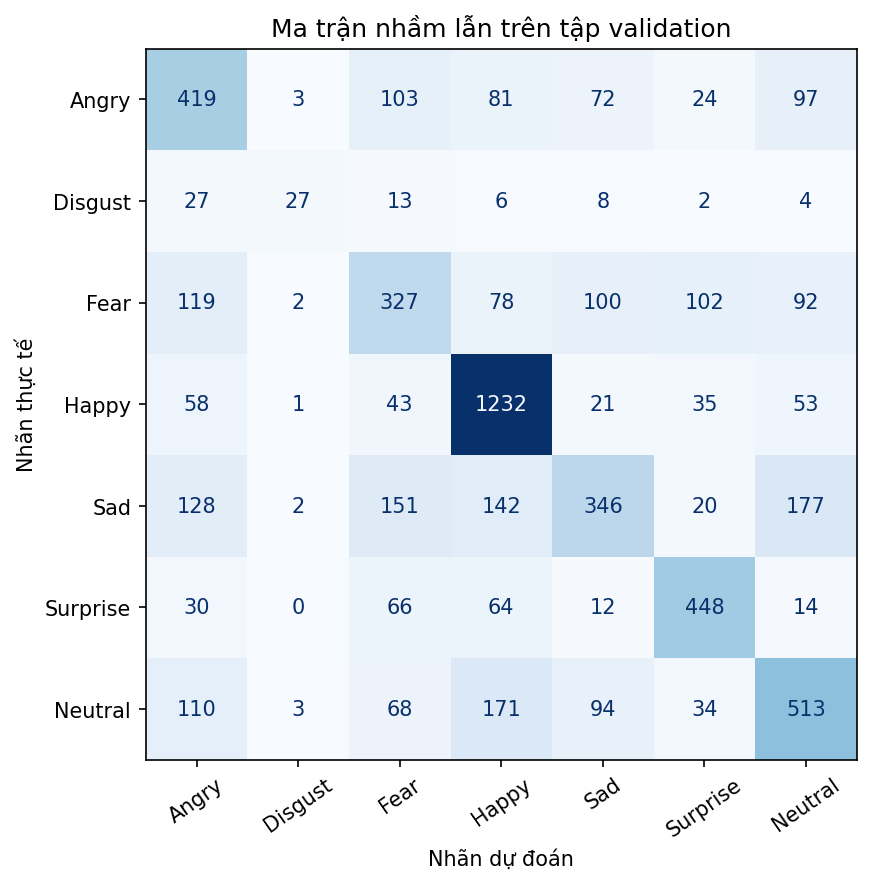

DeeperCNN + BN


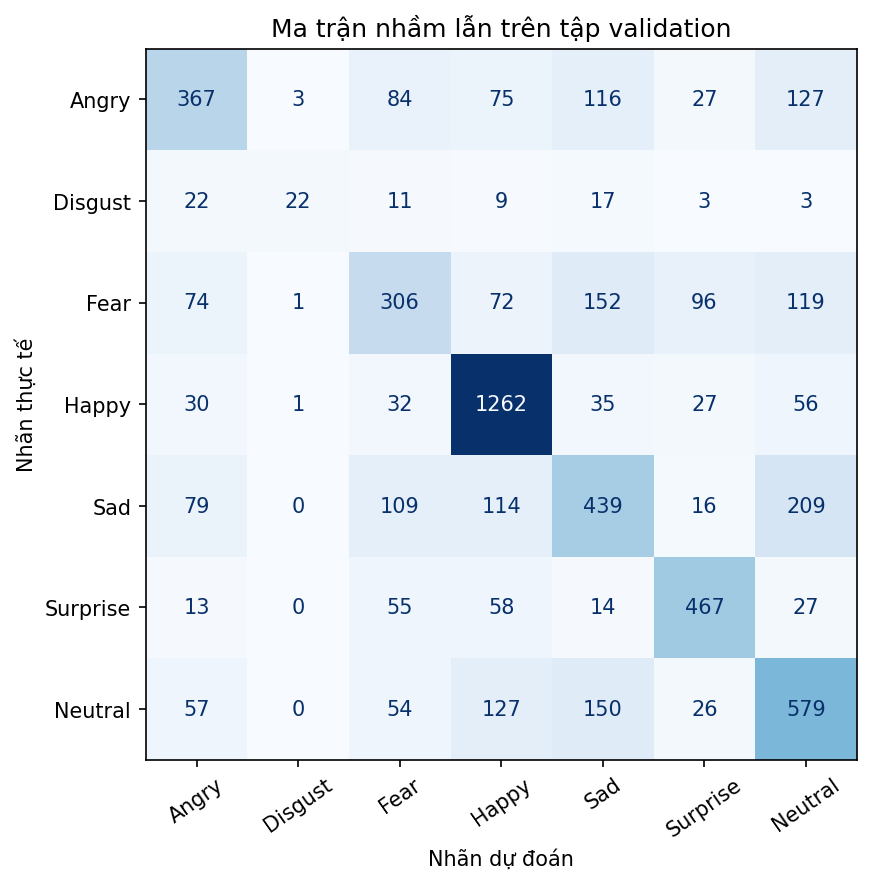

Improved V2 + BN


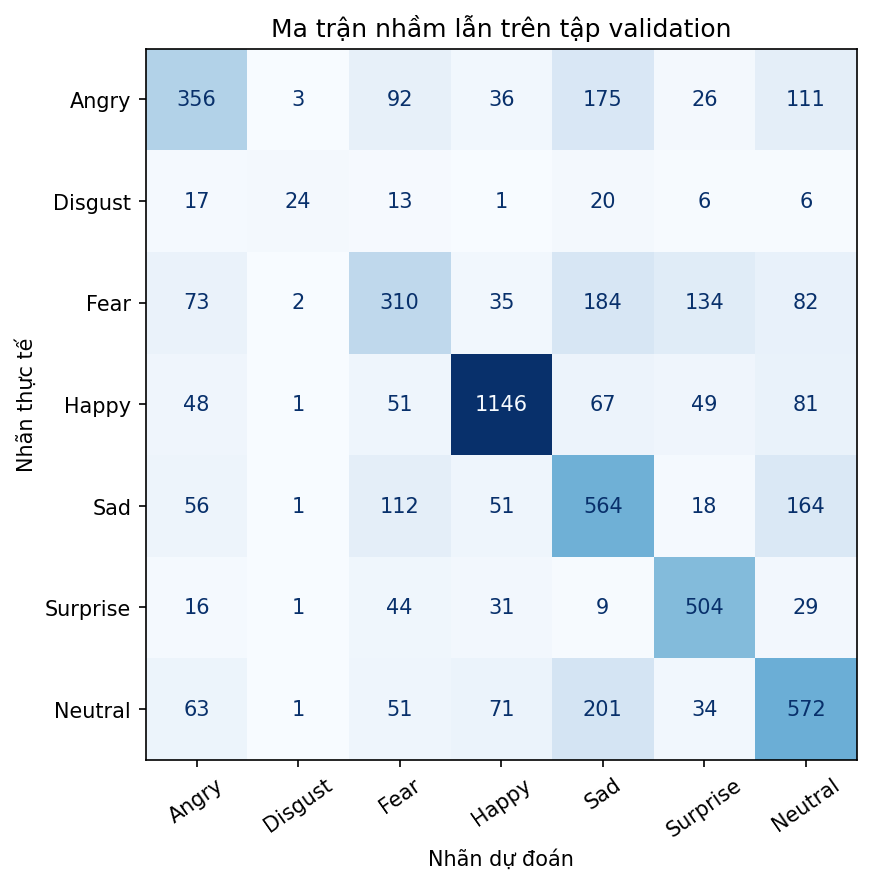

Improved V3 + BN


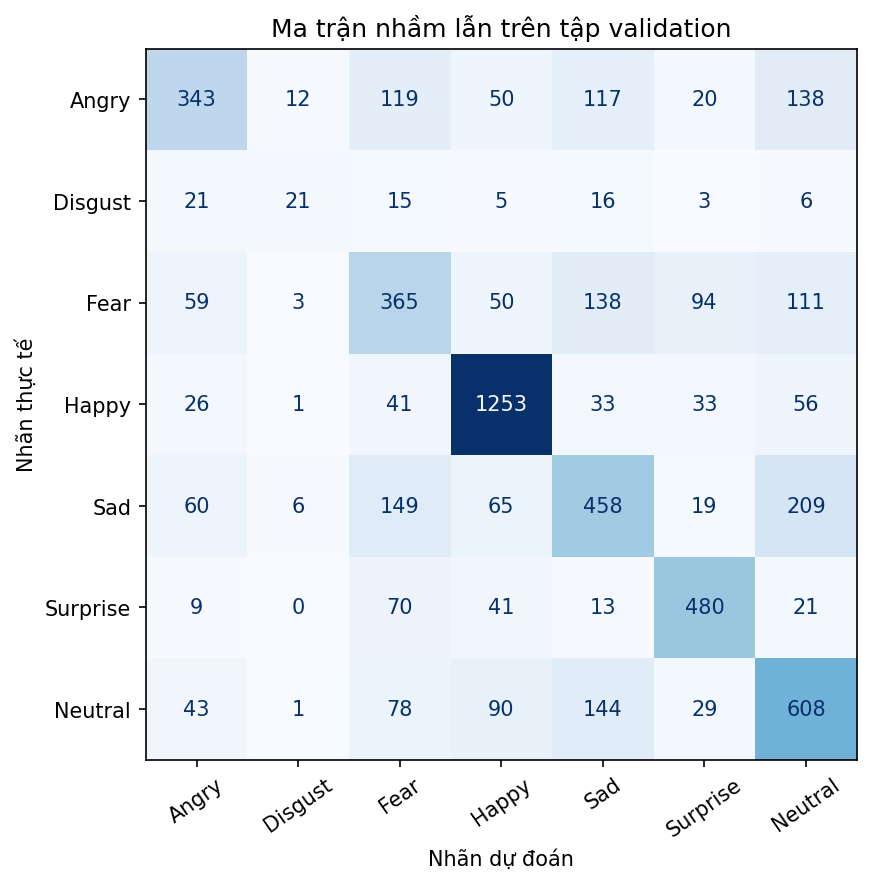

In [4]:
validation_results = {}
for name, run in runs.items():
    evaluation_path = run / "evaluation.json"
    if evaluation_path.is_file():
        saved = json.loads(evaluation_path.read_text(encoding="utf-8"))
    else:
        saved = None

    if saved is None or saved.get("split") != "validation":
        run_config = yaml.safe_load((run / "config.yaml").read_text(encoding="utf-8"))
        saved = evaluate_checkpoint(
            run,
            project / run_config["data_dir"],
            run_config["batch_size"],
            select_device(run_config.get("device", "auto")),
            split="validation",
        )
    validation_results[name] = saved

validation_summary = pd.DataFrame.from_dict(
    {
        name: {
            "Validation accuracy (%)": 100 * result["accuracy"],
            "Validation macro F1": result["macro_f1"],
        }
        for name, result in validation_results.items()
    },
    orient="index",
)
display(validation_summary.round(4))

for name in EXP03_CONFIG_PATHS:
    run = runs[name]
    print(name)
    display(Image(filename=str(run / "confusion_matrix.png"), width=680))

## So sánh hiệu quả Batch Normalization trên validation

,Epoch được chọn,Validation loss,Validation accuracy (%),Validation macro F1,Số tham số,Thời gian (giây),Thiết bị,Δ loss,Δ accuracy (điểm %)
Baseline (EXP01),8,1.1995,55.2072,0.4861,683527,1570.0759,CPU,0.0000,0.0000
DeeperCNN (EXP02),7,1.2117,54.4584,0.4874,831111,103.5085,NVIDIA GeForce RTX 3050 Laptop GPU,0.0122,-0.7489
Improved V2 (EXP02),6,1.1746,56.0432,0.4875,877287,185.9099,NVIDIA GeForce RTX 3050 Laptop GPU,-0.0250,0.8359
Improved V3 (EXP02),10,1.2639,53.2741,0.4582,1467623,229.7135,NVIDIA GeForce RTX 3050 Laptop GPU,0.0644,-1.9331
Baseline + BN,4,1.1529,57.6803,0.5357,683879,95.0237,NVIDIA GeForce RTX 3050 Laptop GPU,-0.0466,2.4730
DeeperCNN + BN,4,1.0913,59.9443,0.5491,831591,122.6453,NVIDIA GeForce RTX 3050 Laptop GPU,-0.1082,4.7370
Improved V2 + BN,4,1.0690,60.5364,0.5605,877863,219.6235,NVIDIA GeForce RTX 3050 Laptop GPU,-0.1305,5.3292
Improved V3 + BN,4,1.0388,61.4420,0.5553,1468711,265.0678,NVIDIA GeForce RTX 3050 Laptop GPU,-0.1607,6.2348


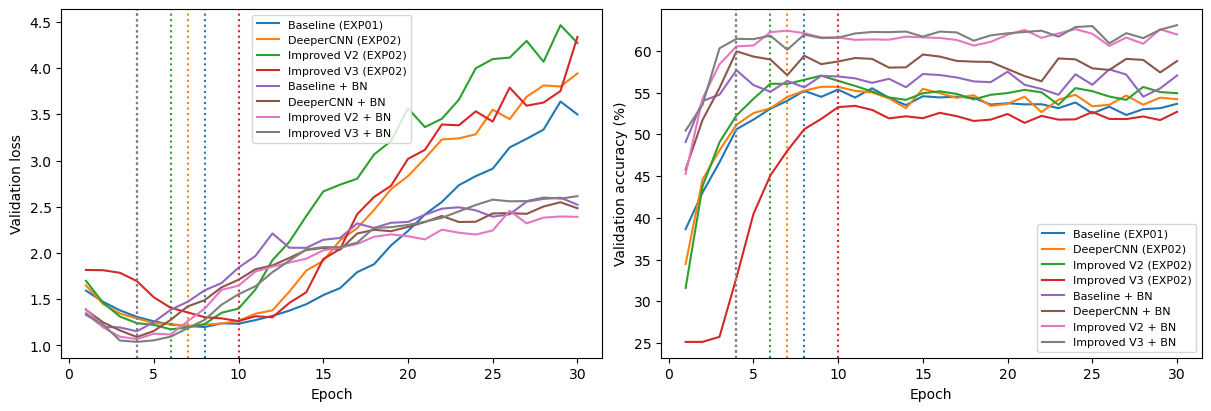

In [5]:
baseline_ref = "Baseline (EXP01)"
comparison = {}
histories = {}
for name, run in runs.items():
    summary = json.loads((run / "training.json").read_text(encoding="utf-8"))
    history = pd.read_csv(run / "history.csv")
    best = history.loc[history["epoch"] == summary["best_epoch"]].iloc[0]
    histories[name] = history
    comparison[name] = {
        "Epoch được chọn": summary["best_epoch"],
        "Validation loss": best["val_loss"],
        "Validation accuracy (%)": 100 * validation_results[name]["accuracy"],
        "Validation macro F1": validation_results[name]["macro_f1"],
        "Số tham số": summary["parameters"],
        "Thời gian (giây)": summary["training_seconds"],
        "Thiết bị": summary["hardware"],
    }

table = pd.DataFrame.from_dict(comparison, orient="index")
table["Δ loss"] = table["Validation loss"] - table.loc[baseline_ref, "Validation loss"]
table["Δ accuracy (điểm %)"] = (
    table["Validation accuracy (%)"] - table.loc[baseline_ref, "Validation accuracy (%)"]
)
display(table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, metric, label in zip(
    axes, ("val_loss", "val_accuracy"), ("Validation loss", "Validation accuracy (%)")
):
    for name, history in histories.items():
        values = history[metric] * 100 if metric == "val_accuracy" else history[metric]
        line, = ax.plot(history["epoch"], values, label=name)
        ax.axvline(comparison[name]["Epoch được chọn"], color=line.get_color(), linestyle=":")
    ax.set(xlabel="Epoch", ylabel=label)
    ax.legend(fontsize=8)
plt.show()